# Home Assignment 2: Six-Class IMU Gesture Recognition

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import tensorflow as tf
import tensorflow_model_optimization as tfmot
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'data' / 'provided').is_dir():
    ROOT = ROOT / 'submission' / 'ha2' / 'imu'
sys.path.insert(0, str(ROOT))
from training import (
    ARCHITECTURE_RUNS, CLASS_NAMES, build_model, convert_to_int8,
    evaluate_tflite, measure_pico_latency, prepare_dataset,
    train_architectures, train_pruned_and_qat, write_pico_artifacts,
    write_results_csv,
)

ARTIFACTS = ROOT / 'artifacts'
PICO_DIR = ROOT / 'pico'
DEPLOY_VARIANT = 'baseline_cnn_qat'  # Selected model for live Pico inference.
ARTIFACTS.mkdir(parents=True, exist_ok=True)
print('TensorFlow:', tf.__version__)
print('TFMOT:', tfmot.__version__)
print('Classes:', CLASS_NAMES)


TensorFlow: 2.16.2
TFMOT: 0.8.1
Classes: ('negative', 'ring', 'slope', 'wing', 'ramp', 'triangle')


## 1. Dataset and split

In [2]:
provided_dir = ROOT / 'data' / 'provided'
counts = {name: len(list((provided_dir / name).glob('*.txt'))) for name in CLASS_NAMES}
assert all(count == 50 for count in counts.values()), counts
display(pd.DataFrame.from_dict(counts, orient='index', columns=['provided recordings']))
data = prepare_dataset(provided_dir, seed=42)
print('Fixed class order:', dict(enumerate(CLASS_NAMES)))
print('Split sizes:', {name: len(data[f'y_{name}']) for name in ('train', 'validation', 'test')})
print('Input shape:', data['X_train'].shape[1:])
print('Training mean (g):', data['mean'])
print('Training std (g):', data['std'])
display(pd.DataFrame(data['file_counts']).T)

,provided recordings
negative,50
ring,50
slope,50
wing,50
ramp,50
triangle,50


Fixed class order: {0: 'negative', 1: 'ring', 2: 'slope', 3: 'wing', 4: 'ramp', 5: 'triangle'}
Split sizes: {'train': 210, 'validation': 42, 'test': 48}
Input shape: (128, 3, 1)
Training mean (g): [-6.9105835e-04 -6.6164143e-02  1.0025522e+00]
Training std (g): [0.15719594 0.18102309 0.23996079]


,train,validation,test
negative,35,7,8
ring,35,7,8
slope,35,7,8
wing,35,7,8
ramp,35,7,8
triangle,35,7,8


## 2. Architecture and hyperparameter comparison

The trials compare a compact Conv2D CNN, a depthwise-separable CNN, and six LSTM configurations. The LSTM trials vary hidden units, dropout, learning rate, batch size, and Adam versus RMSprop; the CNN trial also varies dropout, learning rate, and batch size. All runs use the same fixed data split and early stopping. Validation accuracy selects models; test accuracy is held back for reporting. With 50 recordings per class, the split has 210 training, 42 validation, and 48 test examples, so each validation/test example changes accuracy by about 2.4/2.1 percentage points. Compare train and validation accuracy to identify under/overfitting; treat one split as a small-sample estimate.

In [3]:
trained, best_architecture, architecture_rows = train_architectures(
    data, ARTIFACTS / 'keras', epochs=60
)
print('Best architecture by validation accuracy:', best_architecture)
display(pd.DataFrame(architecture_rows).sort_values('validation_accuracy', ascending=False))



Epoch 1/60


14/14 - 23s - loss: 1.4786 - accuracy: 0.5095 - val_loss: 1.0652 - val_accuracy: 0.5952 - lr: 0.0010 - 23s/epoch - 2s/step
Epoch 2/60
14/14 - 0s - loss: 0.7880 - accuracy: 0.7333 - val_loss: 0.6088 - val_accuracy: 0.9286 - lr: 0.0010 - 128ms/epoch - 9ms/step
Epoch 3/60
14/14 - 0s - loss: 0.4020 - accuracy: 0.9286 - val_loss: 0.3597 - val_accuracy: 0.9762 - lr: 0.0010 - 125ms/epoch - 9ms/step
Epoch 4/60
14/14 - 0s - loss: 0.1557 - accuracy: 0.9810 - val_loss: 0.3007 - val_accuracy: 0.9524 - lr: 0.0010 - 121ms/epoch - 9ms/step
Epoch 5/60
14/14 - 0s - loss: 0.0617 - accuracy: 1.0000 - val_loss: 0.3091 - val_accuracy: 0.9762 - lr: 0.0010 - 122ms/epoch - 9ms/step
Epoch 6/60
14/14 - 0s - loss: 0.0304 - accuracy: 1.0000 - val_loss: 0.3162 - val_accuracy: 0.9762 - lr: 0.0010 - 111ms/epoch - 8ms/step
Epoch 7/60
14/14 - 0s - loss: 0.0163 - accuracy: 1.0000 - val_loss: 0.2992 - val_accuracy: 0.9762 - lr: 0.0010 - 125ms/epoch - 9ms/step
Epoch 8/60
14/14 - 0s - loss: 0.0099 - accurac

,model,method,parameters,train_accuracy,validation_accuracy,test_accuracy,own_data_accuracy,model_bytes,host_inference_ms,pico_inference_ms,epochs_run,optimizer,learning_rate,batch_size
0,baseline_cnn,float architecture / hyperparameter trial,37870,0.971429,0.976190,0.916667,0.916667,492662,1.9271,measure on Pico,13,Adam,0.0010,16
4,lstm_48_regularized,float architecture / hyperparameter trial,10278,0.914286,0.976190,0.791667,0.791667,153086,4.1105,measure on Pico,51,Adam,0.0005,16
7,separable_cnn,float architecture / hyperparameter trial,37260,0.928571,0.976190,0.916667,0.916667,494458,2.5352,measure on Pico,17,Adam,0.0005,16
8,tuned_cnn,float architecture / hyperparameter trial,37870,0.980952,0.976190,0.875000,0.875000,495027,1.8236,measure on Pico,16,Adam,0.0005,32
2,lstm_24_units,float architecture / hyperparameter trial,2838,0.938095,0.928571,0.833333,0.833333,63800,4.4707,measure on Pico,33,Adam,0.0010,16
5,lstm_24_fast,float architecture / hyperparameter trial,2838,0.871429,0.904762,0.750000,0.750000,61567,6.1481,measure on Pico,40,Adam,0.0020,32
3,lstm_32_regularized,float architecture / hyperparameter trial,4806,0.800000,0.880952,0.812500,0.812500,87422,4.9695,measure on Pico,36,Adam,0.0005,32
6,lstm_24_rmsprop,float architecture / hyperparameter trial,2838,0.752381,0.833333,0.729167,0.729167,50669,4.5389,measure on Pico,26,RMSprop,0.0010,16
1,lstm_baseline,float architecture / hyperparameter trial,846,0.714286,0.785714,0.750000,0.750000,39896,5.3124,measure on Pico,49,Adam,0.0010,16


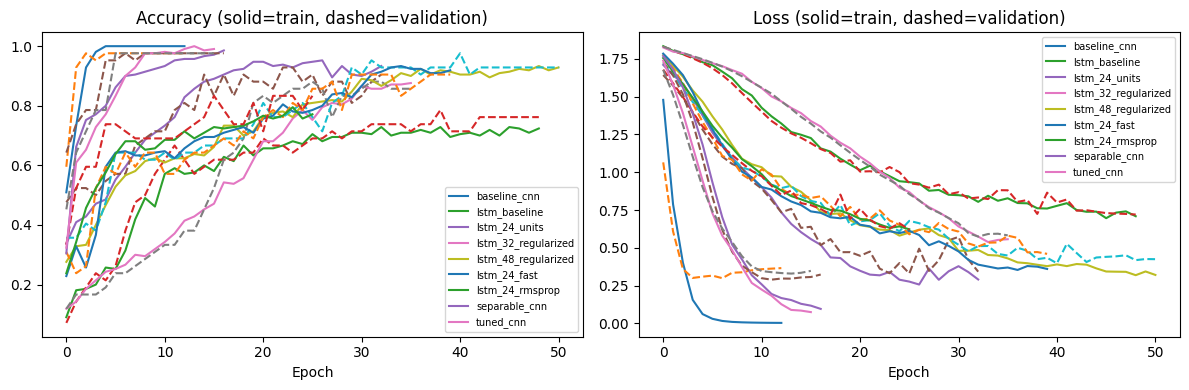

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, run in trained.items():
    axes[0].plot(run['history']['accuracy'], label=name)
    axes[0].plot(run['history']['val_accuracy'], linestyle='--')
    axes[1].plot(run['history']['loss'], label=name)
    axes[1].plot(run['history']['val_loss'], linestyle='--')
axes[0].set_title('Accuracy (solid=train, dashed=validation)')
axes[1].set_title('Loss (solid=train, dashed=validation)')
for axis in axes:
    axis.set_xlabel('Epoch')
    axis.legend(fontsize=7)
plt.tight_layout()

## 3. Quantization, pruning, and QAT



In [5]:
quantized_candidates = {}
for name, run in trained.items():
    content = convert_to_int8(run['model'], data['X_train'])
    (ARTIFACTS / f'{name}_ptq_int8.tflite').write_bytes(content)
    quantized_candidates[f'{name}_ptq'] = {
        'model': run['model'], 'content': content, 'method': 'PTQ',
        'epochs_run': len(run['history']['loss']),
        'optimizer': 'RMSprop' if run['config'].get('optimizer') == 'rmsprop' else 'Adam',
        'learning_rate': run['config']['learning_rate'],
        'batch_size': run['config']['batch_size'],
    }

best_prunable_architecture = max(
    (name for name, run in trained.items() if run['config']['architecture'] != 'lstm'),
    key=lambda name: trained[name]['validation_accuracy'],
)
best_float_model = trained[best_prunable_architecture]['model']
optimized_models, measured_sparsity, optimization_history = train_pruned_and_qat(
    best_float_model, data, ARTIFACTS / 'keras', epochs=30
)
for variant, model in optimized_models.items():
    content = convert_to_int8(model, data['X_train'])
    (ARTIFACTS / f'{best_prunable_architecture}_{variant}_int8.tflite').write_bytes(content)
    method = '50% magnitude pruning + PTQ' if variant == 'pruned' else 'QAT + int8 conversion'
    quantized_candidates[f'{best_prunable_architecture}_{variant}'] = {
        'model': model, 'content': content, 'method': method,
        'epochs_run': optimization_history[f'{variant}_epochs'],
        'learning_rate': 5e-4 if variant == 'pruned' else 2e-4,
        'batch_size': 16,
        'optimizer': 'Adam',
    }
print(f'Pruned-weight sparsity: {measured_sparsity:.1%}')
print('Pruning/QAT epochs:', optimization_history)

INFO:tensorflow:Assets written to: C:\Users\sggoo\AppData\Local\Temp\tmpdt1dwws1\assets


INFO:tensorflow:Assets written to: C:\Users\sggoo\AppData\Local\Temp\tmpdt1dwws1\assets
c:\Users\sggoo\AppData\Local\Programs\Python\Python312\Lib\site-packages\tensorflow\lite\python\convert.py:964: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


INFO:tensorflow:Assets written to: C:\Users\sggoo\AppData\Local\Temp\tmp6xfd9mwi\assets


INFO:tensorflow:Assets written to: C:\Users\sggoo\AppData\Local\Temp\tmp6xfd9mwi\assets
c:\Users\sggoo\AppData\Local\Programs\Python\Python312\Lib\site-packages\tensorflow\lite\python\convert.py:964: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


INFO:tensorflow:Assets written to: C:\Users\sggoo\AppData\Local\Temp\tmpx7adncg8\assets


INFO:tensorflow:Assets written to: C:\Users\sggoo\AppData\Local\Temp\tmpx7adncg8\assets
c:\Users\sggoo\AppData\Local\Programs\Python\Python312\Lib\site-packages\tensorflow\lite\python\convert.py:964: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


... (13 outputs left out)

INFO:tensorflow:Assets written to: C:\Users\sggoo\AppData\Local\Temp\tmppi9lcube\assets
c:\Users\sggoo\AppData\Local\Programs\Python\Python312\Lib\site-packages\tensorflow\lite\python\convert.py:964: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


INFO:tensorflow:Assets written to: C:\Users\sggoo\AppData\Local\Temp\tmpzgldnbl4\assets


INFO:tensorflow:Assets written to: C:\Users\sggoo\AppData\Local\Temp\tmpzgldnbl4\assets
c:\Users\sggoo\AppData\Local\Programs\Python\Python312\Lib\site-packages\tensorflow\lite\python\convert.py:964: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Pruned-weight sparsity: 49.9%
Pruning/QAT epochs: {'pruned_epochs': 30, 'qat_epochs': 9}


In [6]:
comparison_rows = list(architecture_rows)
candidate_scores = {}
for name, candidate in quantized_candidates.items():
    training = evaluate_tflite(candidate['content'], data['X_train'], data['y_train'])
    validation = evaluate_tflite(candidate['content'], data['X_validation'], data['y_validation'])
    test = evaluate_tflite(candidate['content'], data['X_test'], data['y_test'])
    model = candidate['model']
    candidate_scores[name] = validation['accuracy']
    comparison_rows.append({
        'model': name, 'method': candidate['method'],
        'parameters': int(model.count_params()),
        'train_accuracy': training['accuracy'],
        'validation_accuracy': validation['accuracy'],
        'test_accuracy': test['accuracy'],
        'own_data_accuracy': test['accuracy'],
        'model_bytes': len(candidate['content']),
        'host_inference_ms': round(test['average_ms'], 4),
        'pico_inference_ms': 'measure on Pico',
        'epochs_run': candidate['epochs_run'],
        'optimizer': candidate['optimizer'],
        'learning_rate': candidate['learning_rate'],
        'batch_size': candidate['batch_size'],
    })

best_variant = max(candidate_scores, key=candidate_scores.get)
best_candidate = quantized_candidates[best_variant]
print('Best int8 export by validation accuracy:', best_variant, candidate_scores[best_variant])
print('Float architecture summary:')
trained[best_architecture]['model'].summary()
assignment_table = pd.DataFrame(comparison_rows).rename(columns={
    'model': 'Trial', 'method': 'Optimization method', 'epochs_run': 'Epochs',
    'learning_rate': 'Learning rate', 'batch_size': 'Batch size',
    'optimizer': 'Optimizer',
    'parameters': 'Parameters', 'model_bytes': 'Model size (bytes)',
    'host_inference_ms': 'Average inference (host ms)',
    'pico_inference_ms': 'Average inference (Pico ms)',
    'train_accuracy': 'Train accuracy', 'validation_accuracy': 'Validation accuracy',
    'own_data_accuracy': 'Self-recorded accuracy (held-out test)',
})
display(assignment_table[[
    'Trial', 'Optimization method', 'Epochs', 'Optimizer', 'Learning rate', 'Batch size',
    'Parameters', 'Model size (bytes)', 'Average inference (host ms)',
    'Average inference (Pico ms)', 'Train accuracy', 'Validation accuracy',
    'Self-recorded accuracy (held-out test)',
]].sort_values('Validation accuracy', ascending=False))

Best int8 export by validation accuracy: baseline_cnn_ptq 0.9761904761904762
Float architecture summary:
Model: "baseline_cnn"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 imu_window (InputLayer)     [(None, 128, 3, 1)]       0         
                                                                 
 conv2d (Conv2D)             (None, 128, 3, 8)         176       
                                                                 
 max_pooling2d (MaxPooling2  (None, 64, 3, 8)          0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 64, 3, 16)         656       
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 32, 3, 16)         0         
 g2D)                                                            
               

,Trial,Optimization method,Epochs,Optimizer,Learning rate,Batch size,Parameters,Model size (bytes),Average inference (host ms),Average inference (Pico ms),Train accuracy,Validation accuracy,Self-recorded accuracy (held-out test)
19,baseline_cnn_qat,QAT + int8 conversion,9,Adam,0.0002,16,37940,43344,0.0263,measure on Pico,0.990476,0.976190,0.895833
18,baseline_cnn_pruned,50% magnitude pruning + PTQ,30,Adam,0.0005,16,37870,42888,0.0257,measure on Pico,1.000000,0.976190,0.916667
17,tuned_cnn_ptq,PTQ,16,Adam,0.0005,32,37870,42832,0.0330,measure on Pico,0.980952,0.976190,0.875000
16,separable_cnn_ptq,PTQ,17,Adam,0.0005,16,37260,43680,0.0217,measure on Pico,0.928571,0.976190,0.916667
9,baseline_cnn_ptq,PTQ,13,Adam,0.0010,16,37870,42888,0.0592,measure on Pico,0.971429,0.976190,0.916667
7,separable_cnn,float architecture / hyperparameter trial,17,Adam,0.0005,16,37260,494458,2.5352,measure on Pico,0.928571,0.976190,0.916667
8,tuned_cnn,float architecture / hyperparameter trial,16,Adam,0.0005,32,37870,495027,1.8236,measure on Pico,0.980952,0.976190,0.875000
0,baseline_cnn,float architecture / hyperparameter trial,13,Adam,0.0010,16,37870,492662,1.9271,measure on Pico,0.971429,0.976190,0.916667
4,lstm_48_regularized,float architecture / hyperparameter trial,51,Adam,0.0005,16,10278,153086,4.1105,measure on Pico,0.914286,0.976190,0.791667
2,lstm_24_units,float architecture / hyperparameter trial,33,Adam,0.0010,16,2838,63800,4.4707,measure on Pico,0.938095,0.928571,0.833333


### Testing another model on the Pico

Setting `DEPLOY_VARIANT` in the setup cell to a saved candidate name such as `baseline_cnn_pruned` or `lstm_24_units_ptq`, rerunning the setup cell and the selector cell below, then rerun the model export cell.

In [ ]:
if DEPLOY_VARIANT is None:
    if 'candidate_scores' not in globals():
        raise ValueError('Set DEPLOY_VARIANT to a saved model name when selecting without running training.')
    best_variant = max(candidate_scores, key=candidate_scores.get)
    best_candidate = quantized_candidates[best_variant]
else:
    candidate_path = ARTIFACTS / f'{DEPLOY_VARIANT}_int8.tflite'
    if not candidate_path.is_file():
        available = sorted(path.name[:-len('_int8.tflite')] for path in ARTIFACTS.glob('*_int8.tflite'))
        raise FileNotFoundError(f'Saved int8 model {candidate_path} not found. Available: {available}')
    best_variant = DEPLOY_VARIANT
    best_candidate = {'content': candidate_path.read_bytes()}
score = candidate_scores.get(best_variant) if 'candidate_scores' in globals() else None
selection = 'manual' if DEPLOY_VARIANT is not None else 'best validation accuracy'
if score is None:
    print(f'Selected {selection} model from saved artifacts:', best_variant)
else:
    print(f'Selected int8 export ({selection}):', best_variant, score)

## 4. accuracy


In [7]:
for row in comparison_rows:
    row['own_data_accuracy'] = row['test_accuracy']

write_results_csv(comparison_rows, ARTIFACTS / 'experiment_results.csv')
display(pd.DataFrame(comparison_rows))

,model,method,parameters,train_accuracy,validation_accuracy,test_accuracy,own_data_accuracy,model_bytes,host_inference_ms,pico_inference_ms,epochs_run,optimizer,learning_rate,batch_size
0,baseline_cnn,float architecture / hyperparameter trial,37870,0.971429,0.976190,0.916667,0.916667,492662,1.9271,measure on Pico,13,Adam,0.0010,16
1,lstm_baseline,float architecture / hyperparameter trial,846,0.714286,0.785714,0.750000,0.750000,39896,5.3124,measure on Pico,49,Adam,0.0010,16
2,lstm_24_units,float architecture / hyperparameter trial,2838,0.938095,0.928571,0.833333,0.833333,63800,4.4707,measure on Pico,33,Adam,0.0010,16
3,lstm_32_regularized,float architecture / hyperparameter trial,4806,0.800000,0.880952,0.812500,0.812500,87422,4.9695,measure on Pico,36,Adam,0.0005,32
4,lstm_48_regularized,float architecture / hyperparameter trial,10278,0.914286,0.976190,0.791667,0.791667,153086,4.1105,measure on Pico,51,Adam,0.0005,16
5,lstm_24_fast,float architecture / hyperparameter trial,2838,0.871429,0.904762,0.750000,0.750000,61567,6.1481,measure on Pico,40,Adam,0.0020,32
6,lstm_24_rmsprop,float architecture / hyperparameter trial,2838,0.752381,0.833333,0.729167,0.729167,50669,4.5389,measure on Pico,26,RMSprop,0.0010,16
7,separable_cnn,float architecture / hyperparameter trial,37260,0.928571,0.976190,0.916667,0.916667,494458,2.5352,measure on Pico,17,Adam,0.0005,16
8,tuned_cnn,float architecture / hyperparameter trial,37870,0.980952,0.976190,0.875000,0.875000,495027,1.8236,measure on Pico,16,Adam,0.0005,32
9,baseline_cnn_ptq,PTQ,37870,0.971429,0.976190,0.916667,0.916667,42888,0.0592,measure on Pico,13,Adam,0.0010,16


## 5. Export the selected Pico model


In [8]:
if 'data' in globals() and 'mean' in data and 'std' in data:
    axis_mean, axis_std = data['mean'], data['std']
else:
    import json
    preprocessing_path = PICO_DIR / 'artifacts' / 'preprocessing.json'
    if not preprocessing_path.is_file():
        raise FileNotFoundError(f'Preprocessing metadata is missing: {preprocessing_path}')
    saved_preprocessing = json.loads(preprocessing_path.read_text(encoding='utf-8'))
    axis_mean = np.asarray(saved_preprocessing['axis_mean'], dtype=np.float32)
    axis_std = np.asarray(saved_preprocessing['axis_std'], dtype=np.float32)
metadata = write_pico_artifacts(
    best_candidate['content'], axis_mean, axis_std, PICO_DIR, CLASS_NAMES
)
print('Exported:', PICO_DIR / 'artifacts' / 'gesture_model.tflite')
print('Labels:', metadata['class_names'])
print('Input quantization:', metadata['input_scale'], metadata['input_zero_point'])
print('Experiment table:', ARTIFACTS / 'experiment_results.csv')

Exported: d:\Dokumente\UniLuebeck\WiSe26\TalTech\MachineLearningForEmbeddedSystems\Git\submission\ha2\imu\pico\artifacts\gesture_model.tflite
Labels: ['negative', 'ring', 'slope', 'wing', 'ramp', 'triangle']
Input quantization: 0.041620612144470215 137
Experiment table: d:\Dokumente\UniLuebeck\WiSe26\TalTech\MachineLearningForEmbeddedSystems\Git\submission\ha2\imu\artifacts\experiment_results.csv


## 6. Record Pico inference latency


In [9]:
PICO_LOG = ARTIFACTS / 'pico_serial.log'
if PICO_LOG.is_file():
    pico_latency = measure_pico_latency(PICO_LOG)
    results_path = ARTIFACTS / 'experiment_results.csv'
    import csv
    with results_path.open('r', newline='', encoding='utf-8') as handle:
        results_rows = list(csv.DictReader(handle))
    selected_row = next((row for row in results_rows if row['model'] == best_variant), None)
    if selected_row is None:
        raise ValueError(f'Model {best_variant!r} is not listed in {results_path}')
    selected_row['pico_inference_ms'] = round(pico_latency['mean_ms'], 4)
    write_results_csv(results_rows, results_path)
    print(f"Pico mean latency: {pico_latency['mean_ms']:.4f} ms over {pico_latency['count']} inferences (std {pico_latency['std_ms']:.4f} ms)")
else:
    print(f'Pico latency pending: save serial output to {PICO_LOG}')

Pico latency pending: save serial output to d:\Dokumente\UniLuebeck\WiSe26\TalTech\MachineLearningForEmbeddedSystems\Git\submission\ha2\imu\artifacts\pico_serial.log
